# First Assignment - Business Process Prediction Simulation, and Optimization - Winter Semester 2026/2027

### Milena Fernanda Rivera Hernández

### **3.1 Technical Setup and Preliminaries**

In [1]:
# First we will list all the libraries that we will use and for what purpose

# Process mining
import pm4py

# Data frames handling
import pandas as pd

# For defining graph axes and do some calculations 
import numpy as np

# Visualizations for additional stats
import matplotlib.pyplot as plt

# Group by case length
import itertools

# Shared metric helpers and joint comparison table
import math




  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




### **3.2 Simple Event Log Analysis**

In [2]:
# So we first access the dowloaded data
log = pm4py.read_xes("data_BPIChallenge2017_1_all/BPI Challenge 2017.xes.gz") 
df = pm4py.convert_to_dataframe(log)

/Users/milenafer/Desktop/PC/First-Assignment-BPPSO-WS26-27/.venv/lib/python3.12/site-packages/pm4py/utils.py:1027: UserWarning: Install the optional requirement `r4pm` to import/export files faster. `rustxes` remains supported as a fallback.
  warnings.warn(
/Users/milenafer/Desktop/PC/First-Assignment-BPPSO-WS26-27/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
parsing log, completed traces :: 100%|██████████| 31509/31509 [01:05<00:00, 481.40it/s]


In [ ]:
from pm4py.objects.log.importer.xes import importer as xes_importer
logg = xes_importer.apply("data_BPIChallenge2017_1_all/BPI Challenge 2017.xes.gz")
 


parsing log, completed traces :: 100%|██████████| 31509/31509 [01:17<00:00, 407.10it/s]


In [37]:
# First trace
logg[0]

{'attributes': {'LoanGoal': 'Existing loan takeover', 'ApplicationType': 'New credit', 'concept:name': 'Application_652823628', 'RequestedAmount': 20000.0}, 'events': [{'Action': 'Created', 'org:resource': 'User_1', 'concept:name': 'A_Create Application', 'EventOrigin': 'Application', 'EventID': 'Application_652823628', 'lifecycle:transition': 'complete', 'time:timestamp': datetime.datetime(2016, 1, 1, 9, 51, 15, 304000, tzinfo=datetime.timezone.utc)}, '..', {'Action': 'Deleted', 'org:resource': 'User_115', 'concept:name': 'W_Validate application', 'EventOrigin': 'Workflow', 'EventID': 'Workitem_2067229931', 'lifecycle:transition': 'ate_abort', 'time:timestamp': datetime.datetime(2016, 1, 14, 15, 49, 11, 423000, tzinfo=datetime.timezone.utc)}]}

In [38]:
# First event in first trace
logg[0][0]

{'Action': 'Created', 'org:resource': 'User_1', 'concept:name': 'A_Create Application', 'EventOrigin': 'Application', 'EventID': 'Application_652823628', 'lifecycle:transition': 'complete', 'time:timestamp': datetime.datetime(2016, 1, 1, 9, 51, 15, 304000, tzinfo=datetime.timezone.utc)}

In [39]:
from pm4py.algo.filtering.log.start_activities import start_activities_filter
from pm4py.algo.filtering.log.end_activities import end_activities_filter

log_start = start_activities_filter.get_start_activities(logg)
end_activities = end_activities_filter.get_end_activities(logg)
log_start  # Printing the start activity in our log

AttributeError: module 'pm4py.algo.filtering.log.start_activities.start_activities_filter' has no attribute 'get_start_activities'

In [3]:
# Just to get to know with what we will be working
print(df.shape)
df.head(5)

(1202267, 19)


,Action,org:resource,concept:name,EventOrigin,EventID,lifecycle:transition,time:timestamp,case:LoanGoal,case:ApplicationType,case:concept:name,case:RequestedAmount,FirstWithdrawalAmount,NumberOfTerms,Accepted,MonthlyCost,Selected,CreditScore,OfferedAmount,OfferID
0,Created,User_1,A_Create Application,Application,Application_652823628,complete,2016-01-01 09:51:15.304000+00:00,Existing loan takeover,New credit,Application_652823628,20000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,statechange,User_1,A_Submitted,Application,ApplState_1582051990,complete,2016-01-01 09:51:15.352000+00:00,Existing loan takeover,New credit,Application_652823628,20000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Created,User_1,W_Handle leads,Workflow,Workitem_1298499574,schedule,2016-01-01 09:51:15.774000+00:00,Existing loan takeover,New credit,Application_652823628,20000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Deleted,User_1,W_Handle leads,Workflow,Workitem_1673366067,withdraw,2016-01-01 09:52:36.392000+00:00,Existing loan takeover,New credit,Application_652823628,20000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Created,User_1,W_Complete application,Workflow,Workitem_1493664571,schedule,2016-01-01 09:52:36.403000+00:00,Existing loan takeover,New credit,Application_652823628,20000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
print(df["time:timestamp"].dtype) # microseconds is our time lowest granularity

datetime64[us, UTC]


In [5]:
# To report simple statistics about the data log we must map each 'column/attribute' to easy variables
case = "case:concept:name"
act = "concept:name"
timestamp = "time:timestamp"
resource = "org:resource"
lifec = "lifecycle:transition"

In [6]:
# Number of cases 
num_cases = df[case].nunique()
print(num_cases) # 31509

31509


In [7]:
# Number of events
num_events = len(df)
print(num_events) # 1202267

1202267


In [8]:
# Number of process variants
num_proc_var = len(pm4py.get_variants(df))
print(num_proc_var) # 15930

15930


In [9]:
# Number of distinct case and event attribute labels

# For case
# First we must figure out the attribute labels
case_attributes = [col for col in df.columns if col.startswith("case:")]
# Check line
print(case_attributes)

num_dist_case_labels = len(case_attributes)
print(num_dist_case_labels)

# For event

# NOTE: Metadata lists only the global attributes that every event has. So if we add offer-related ones we have more.
# We should define in which ones we are interested in (global only for example). 
global_categorical_events = ["Action", "EventID", "EventOrigin","concept:name", "lifecycle:transition", "org:resource", "time:timestamp"] # EventID
#event_attributes = [c for c in global_categorical_events if c in df.columns] # 7 attributes

# Real attributes
event_attributes = [c for c in df.columns if not c.startswith("case:") and not c.startswith("@@")] # 15 attributes

# categorical event attributes = non-numeric, non-datetime event-level columns
categorical_event_attributes = df[event_attributes].select_dtypes(include=['object', 'str', 'category']).columns 

# Check line
print(event_attributes)

num_dist_event_labels = len(event_attributes)
print(num_dist_event_labels)

# print(categorical_event_attributes)
# print(len(categorical_event_attributes))

['case:LoanGoal', 'case:ApplicationType', 'case:concept:name', 'case:RequestedAmount']
4
['Action', 'org:resource', 'concept:name', 'EventOrigin', 'EventID', 'lifecycle:transition', 'time:timestamp', 'FirstWithdrawalAmount', 'NumberOfTerms', 'Accepted', 'MonthlyCost', 'Selected', 'CreditScore', 'OfferedAmount', 'OfferID']
15


In [10]:
# Mean and standard deviation of case length

# First we must figure out events per case
case_len = df.groupby(case).size()

# Mean
cl_mean = case_len.mean()
# Check line
print(cl_mean) # 38.15

# STD
cl_std = case_len.std()
# Check line
print(cl_std) # 16.715

38.15630454790695
16.71530805656438


In [11]:
# Mean and standard deviation of case duration 

# First we must calculate the case duration
# We extract the corresponding timestamps
case_timestamp = df.groupby(case)[timestamp]
durationn = (case_timestamp.max() - case_timestamp.min()).dt.total_seconds() # we should keep it in our finnest required granularity which are seconds for further calculations

# days ******

# Mean
mean_days = durationn.mean() / 86400
# Check line
print(mean_days)

# STD
std_days = durationn.std() / 86400
# Check line
print(std_days)

# minutes ****

# Mean
mean_minutes = durationn.mean() / 60
# Check line
print(mean_minutes)

# STD
std_minutes = durationn.std() / 60
# Check line
print(std_minutes)

# seconds *****

# Mean
mean_secs = durationn.mean()
# Check line
print(mean_secs)

# STD
std_secs = durationn.std()
# Check line
print(std_secs)


21.899605591087365
13.1692325332843
31535.432051165804
18963.694847929393
1892125.9230699483
1137821.6908757635


In [12]:
# Number of categorical event attributes
num_cat_events_att = len(categorical_event_attributes)
# Check line
print(num_cat_events_att)

9


In [13]:
# Table with the required statistics

table_4_stats = pd.DataFrame({
    "Statistic": ["Number of cases",
                  "Number of events",
                  "Number of process variants",
                  "Number of distinct case attribute labels",
                  "Number of distinct event attribute labels",
                  "Case length mean", 
                  "Case length std", 
                  "Case duration mean (days)",
                  "Case duration std (days)",
                  "Case duration mean (minutes)",
                  "Case duration std (minutes)",
                  "Case duration mean (seconds)",
                  "Case duration std (seconds)",
                  "Number of categorical event attributes"],
    "Value" :[f"{num_cases:,}",
              f"{num_events:,}",
              f"{num_proc_var:,}",
              num_dist_case_labels,
              num_dist_event_labels,
              f"{cl_mean:.3f}",
              f"{cl_std:.3f}",
              f"{mean_days:.3f}",
              f"{std_days:.3f}",
              f"{mean_minutes:,.3f}",
              f"{std_minutes:,.3f}",
              f"{mean_secs:,.3f}",
              f"{std_secs:,.3f}",
              num_cat_events_att]})

display(table_4_stats)


,Statistic,Value
0,Number of cases,"31,509"
1,Number of events,"1,202,267"
2,Number of process variants,"15,930"
3,Number of distinct case attribute labels,4
4,Number of distinct event attribute labels,15
5,Case length mean,38.156
6,Case length std,16.715
7,Case duration mean (days),21.900
8,Case duration std (days),13.169
9,Case duration mean (minutes),"31,535.432"


#### **Case-level table**

In [14]:
# For what I intent to add as additional statistics it is required a one case-level table so we must build it first

# Access possible actions, (They are 26 activity names in the log)
print(df[act].unique())


# NOTE: df is sorted by case and timestamp

# duration in days must be calculated using the previous durationn variable
dur_days = durationn / 86400 

# distinct cases can be obtain grouping by the case columns
cases = df.groupby(case).agg(loan_goal=("case:LoanGoal", "first"),
                             app_type=("case:ApplicationType", "first"),
                             amount=("case:RequestedAmount", "first"),
                             n_events=(act, "size"))

cases["duration_days"] = dur_days # NOTE: it is aligned by case ID

# NOTE: The outcome is the last of these activities in each case
outcome_acts = ["A_Pending", "A_Denied", "A_Cancelled"]
last_outcome = (df[df[act].isin(outcome_acts)].groupby(case)[act].last())

# NOTE: 98 cases are applications still open when the log ends, so “No decision yet” says what they are.
cases["outcome"] = last_outcome.reindex(cases.index).fillna("No decision yet")

print(cases["outcome"].value_counts())  

<StringArray>
[      'A_Create Application',                'A_Submitted',
             'W_Handle leads',     'W_Complete application',
                  'A_Concept',                 'A_Accepted',
             'O_Create Offer',                  'O_Created',
   'O_Sent (mail and online)',        'W_Call after offers',
                 'A_Complete',     'W_Validate application',
               'A_Validating',                 'O_Returned',
    'W_Call incomplete files',               'A_Incomplete',
                 'O_Accepted',                  'A_Pending',
                   'A_Denied',                  'O_Refused',
                'O_Cancelled',                'A_Cancelled',
       'O_Sent (online only)',   'W_Assess potential fraud',
 'W_Personal Loan collection',    'W_Shortened completion ']
Length: 26, dtype: str
outcome
A_Pending          17228
A_Cancelled        10431
A_Denied            3752
No decision yet       98
Name: count, dtype: int64


In [15]:
display(cases[:5]) # Just to visualise the final table

,loan_goal,app_type,amount,n_events,duration_days,outcome
case:concept:name,,,,,,
Application_1000086665,"Other, see explanation",New credit,5000.0,22,32.585593,A_Cancelled
Application_1000158214,Home improvement,New credit,12500.0,25,8.033037,A_Pending
Application_1000311556,Car,New credit,45000.0,18,30.586242,A_Cancelled
Application_1000334415,"Other, see explanation",New credit,5000.0,40,13.629359,A_Denied
Application_1000339879,Existing loan takeover,New credit,37500.0,51,12.843500,A_Pending


### **Important questions before additional stats**

- How does a case typically look like?
- How do long cases look like? 
- How do short ones look like?

In [16]:
# To asnwer tihs questions, or at least visualize them, we must group the cases by lenght, for that; we will use 10th and 90th percentils
p10, p90 = cases["n_events"].quantile([0.10, 0.90])
cases["length_group"] = np.select([cases["n_events"] <= p10, 
                                   cases["n_events"] >= p90],
                                  ["short", "long"], 
                                  default="typical")

order_len = ["short", "typical", "long"] # this can change to convenience :)
print(f"- short: <= {p10:.0f} events")
print(f"- long: >= {p90:.0f} events")
display(cases["length_group"].value_counts()[order_len])

- short: <= 21 events
- long: >= 60 events


length_group
short       3544
typical    24695
long        3270
Name: count, dtype: int64

In [17]:
# It is necessary a profile of each group (meaning the "typical look" but in numbers)
cases["n_offers"] = (df[df[act] == "O_Create Offer"].groupby(case).size().reindex(cases.index).fillna(0).astype(int))
 
profile = cases.groupby("length_group").agg(cases = ("n_events", "size"),
                                            events_mean = ("n_events", "mean"),
                                            days_median = ("duration_days", "median"),
                                            offers_mean = ("n_offers", "mean")).loc[order_len]
outcome_mix = (pd.crosstab(cases["length_group"], cases["outcome"], normalize="index") * 100).loc[order_len]

# Profile
profile = profile.join(outcome_mix[["A_Pending", "A_Cancelled", "A_Denied"]].add_prefix("% "))
display(profile.round(2))

,cases,events_mean,days_median,offers_mean,% A_Pending,% A_Cancelled,% A_Denied
length_group,,,,,,,
short,3544,19.25,30.79,1.02,0.17,96.95,2.57
typical,24695,36.15,16.73,1.34,58.55,27.35,13.80
long,3270,73.83,25.71,1.93,84.53,7.40,7.74


In [18]:
# Average number of events per case and activity
grp = df[case].map(cases["length_group"])
per_case = (df.groupby([grp, df[act]]).size().unstack(0)[order_len].div(cases["length_group"].value_counts()[order_len]).fillna(0))
display(per_case.round(2))

case:concept:name,short,typical,long
concept:name,,,
A_Accepted,1.00,1.00,1.00
A_Cancelled,0.97,0.27,0.07
A_Complete,0.97,1.00,1.00
A_Concept,1.00,1.00,1.00
A_Create Application,1.00,1.00,1.00
A_Denied,0.03,0.14,0.08
A_Incomplete,0.00,0.60,2.55
A_Pending,0.00,0.59,0.85
A_Submitted,0.48,0.67,0.70


In [19]:
# Representative = one representative case of certain group which is closest to median lenght and duration

# Auxiliar function 1
def representative(group):
        """
        Identifies the most representative case ID for a specified length group by finding the case with the most frequent outcome 
        and the minimal standardized distance from the group's median event count and duration.
        -------
        Params:
                - group (str): The categorical label of the case length group to filter and analyze (e.g., 'short', 'typical', 'long').
        -------
        Return:
                - str or int: The unique case identifier (DataFrame index) matching the most representative case.
        """
        sub = cases[cases["length_group"] == group]
        sub = sub[sub["outcome"] == sub["outcome"].mode()[0]]
        dist = (((sub["n_events"] - sub["n_events"].median()) / sub["n_events"].std()) ** 2
                + ((sub["duration_days"] - sub["duration_days"].median()) / sub["duration_days"].std()) ** 2)
        return dist.idxmin()


rep = {g: representative(g) for g in order_len} # This are our "Representatives" of each class
display(cases.loc[list(rep.values()), ["loan_goal", "app_type", "amount", "n_events", "duration_days", "outcome"]].set_axis(order_len))


,loan_goal,app_type,amount,n_events,duration_days,outcome
short,Car,Limit raise,12750.0,20,30.805842,A_Cancelled
typical,Car,New credit,20000.0,39,13.797108,A_Pending
long,Remaining debt home,New credit,35000.0,70,24.764548,A_Pending


In [20]:
# Auxiliar funtion 2
def show_case(case_id, max_rows=None):
    """
    Extracts the event log sequence for a specific case ID, including key attributes and calculating the elapsed time 
    since the start of the case.
    -------
    Params:
        - case_id (str or int): The unique identifier of the case to extract.
        - max_rows (int, optional): The maximum number of event rows to return. Defaults to None which returns all events.
    -------
    Return:
        - pandas.DataFrame: A DataFrame containing the case's chronological events and a 'since_start' time delta column.
    """
    trace = df.loc[df[case] == case_id, [timestamp, act, lifec, resource]].reset_index(drop=True) # The trace is our chronological sequence of events
    trace["since_start"] = (trace[timestamp] - trace[timestamp].iloc[0]).dt.round("s")
    return trace if max_rows is None else trace.head(max_rows)


# Auxiliar function 3
def compact_trace(case_id):
    """
    Generates a concise string representation of a case's activity sequence, collapsing consecutive identical activities 
    into multipliers (e.g., 'Activity (X3)').
    -------
    Params: 
        - case_id (str or int): The unique identifier of the case to summarize.
    -------
    Return:
        - str: A formatted string showing the chronological flow of activities connected by arrows.
    """    
    seq = df.loc[df[case] == case_id, act].tolist()
    runs = [(a, sum(1 for _ in g)) for a, g in itertools.groupby(seq)]
    return "\n".join(f"{'    ' * i}↳ {a} (x{n})" if n > 1 else f"{'    ' * i}↳ {a}" for i, (a, n) in enumerate(runs))

In [21]:
# Typical case
print(rep["typical"])
print(compact_trace(rep["typical"]))
show_case(rep["typical"])

Application_938184987
↳ A_Create Application
    ↳ A_Submitted
        ↳ W_Handle leads (x2)
            ↳ W_Complete application
                ↳ A_Concept
                    ↳ W_Complete application
                        ↳ A_Accepted
                            ↳ O_Create Offer
                                ↳ O_Created
                                    ↳ O_Sent (mail and online)
                                        ↳ W_Complete application
                                            ↳ W_Call after offers (x2)
                                                ↳ A_Complete
                                                    ↳ W_Call after offers (x4)
                                                        ↳ W_Validate application (x2)
                                                            ↳ A_Validating
                                                                ↳ O_Returned
                                                                    ↳ W_Validate application (

,time:timestamp,concept:name,lifecycle:transition,org:resource,since_start
0,2016-12-06 15:20:25.013000+00:00,A_Create Application,complete,User_1,0 days 00:00:00
1,2016-12-06 15:20:26.087000+00:00,A_Submitted,complete,User_1,0 days 00:00:01
2,2016-12-06 15:20:26.390000+00:00,W_Handle leads,schedule,User_1,0 days 00:00:01
3,2016-12-06 15:21:00.460000+00:00,W_Handle leads,withdraw,User_1,0 days 00:00:35
4,2016-12-06 15:21:00.466000+00:00,W_Complete application,schedule,User_1,0 days 00:00:35
5,2016-12-06 15:21:00.469000+00:00,A_Concept,complete,User_1,0 days 00:00:35
6,2016-12-07 14:17:13.289000+00:00,W_Complete application,start,User_94,0 days 22:56:48
7,2016-12-07 14:22:59.435000+00:00,A_Accepted,complete,User_94,0 days 23:02:34
8,2016-12-07 14:24:05.829000+00:00,O_Create Offer,complete,User_94,0 days 23:03:41
9,2016-12-07 14:24:06.387000+00:00,O_Created,complete,User_94,0 days 23:03:41


In [22]:
# Short case
print(rep["short"])
print(compact_trace(rep["short"]))
show_case(rep["short"])

Application_930390995
↳ A_Create Application
    ↳ A_Concept
        ↳ W_Complete application (x4)
            ↳ A_Accepted
                ↳ O_Create Offer
                    ↳ O_Created
                        ↳ O_Sent (mail and online)
                            ↳ W_Complete application
                                ↳ W_Call after offers (x2)
                                    ↳ A_Complete
                                        ↳ W_Call after offers (x3)
                                            ↳ A_Cancelled
                                                ↳ O_Cancelled
                                                    ↳ W_Call after offers


,time:timestamp,concept:name,lifecycle:transition,org:resource,since_start
0,2016-12-07 11:40:10.418000+00:00,A_Create Application,complete,User_62,0 days 00:00:00
1,2016-12-07 11:40:10.420000+00:00,A_Concept,complete,User_62,0 days 00:00:00
2,2016-12-07 11:40:10.425000+00:00,W_Complete application,schedule,User_62,0 days 00:00:00
3,2016-12-07 11:40:10.427000+00:00,W_Complete application,start,User_62,0 days 00:00:00
4,2016-12-07 11:40:45.914000+00:00,W_Complete application,suspend,User_62,0 days 00:00:35
5,2016-12-07 12:24:49.942000+00:00,W_Complete application,resume,User_98,0 days 00:44:40
6,2016-12-07 12:30:36.317000+00:00,A_Accepted,complete,User_98,0 days 00:50:26
7,2016-12-07 12:35:25.340000+00:00,O_Create Offer,complete,User_98,0 days 00:55:15
8,2016-12-07 12:35:25.862000+00:00,O_Created,complete,User_98,0 days 00:55:15
9,2016-12-07 12:36:45.676000+00:00,O_Sent (mail and online),complete,User_98,0 days 00:56:35


In [23]:
# Long case 
print(rep["long"])
print(compact_trace(rep["long"]))
show_case(rep["long"], max_rows=25) # without max_rows=25 it is 70

Application_1264855362
↳ A_Create Application
    ↳ A_Submitted
        ↳ W_Handle leads (x2)
            ↳ W_Complete application
                ↳ A_Concept
                    ↳ W_Complete application
                        ↳ A_Accepted
                            ↳ O_Create Offer
                                ↳ O_Created
                                    ↳ O_Sent (mail and online)
                                        ↳ W_Complete application
                                            ↳ W_Call after offers (x2)
                                                ↳ A_Complete
                                                    ↳ W_Call after offers (x7)
                                                        ↳ W_Validate application (x2)
                                                            ↳ A_Validating
                                                                ↳ O_Returned
                                                                    ↳ W_Validate application 

,time:timestamp,concept:name,lifecycle:transition,org:resource,since_start
0,2016-02-26 14:25:25.307000+00:00,A_Create Application,complete,User_1,0 days 00:00:00
1,2016-02-26 14:25:25.346000+00:00,A_Submitted,complete,User_1,0 days 00:00:00
2,2016-02-26 14:25:25.700000+00:00,W_Handle leads,schedule,User_1,0 days 00:00:00
3,2016-02-26 14:26:10.534000+00:00,W_Handle leads,withdraw,User_1,0 days 00:00:45
4,2016-02-26 14:26:10.545000+00:00,W_Complete application,schedule,User_1,0 days 00:00:45
5,2016-02-26 14:26:10.550000+00:00,A_Concept,complete,User_1,0 days 00:00:45
6,2016-02-26 19:41:56.899000+00:00,W_Complete application,start,User_27,0 days 05:16:32
7,2016-02-26 19:52:19.698000+00:00,A_Accepted,complete,User_27,0 days 05:26:54
8,2016-02-26 19:54:58.215000+00:00,O_Create Offer,complete,User_27,0 days 05:29:33
9,2016-02-26 19:54:59.629000+00:00,O_Created,complete,User_27,0 days 05:29:34


### **Additional stats and their visualizations**

#### **Case duration & outcome distribution**

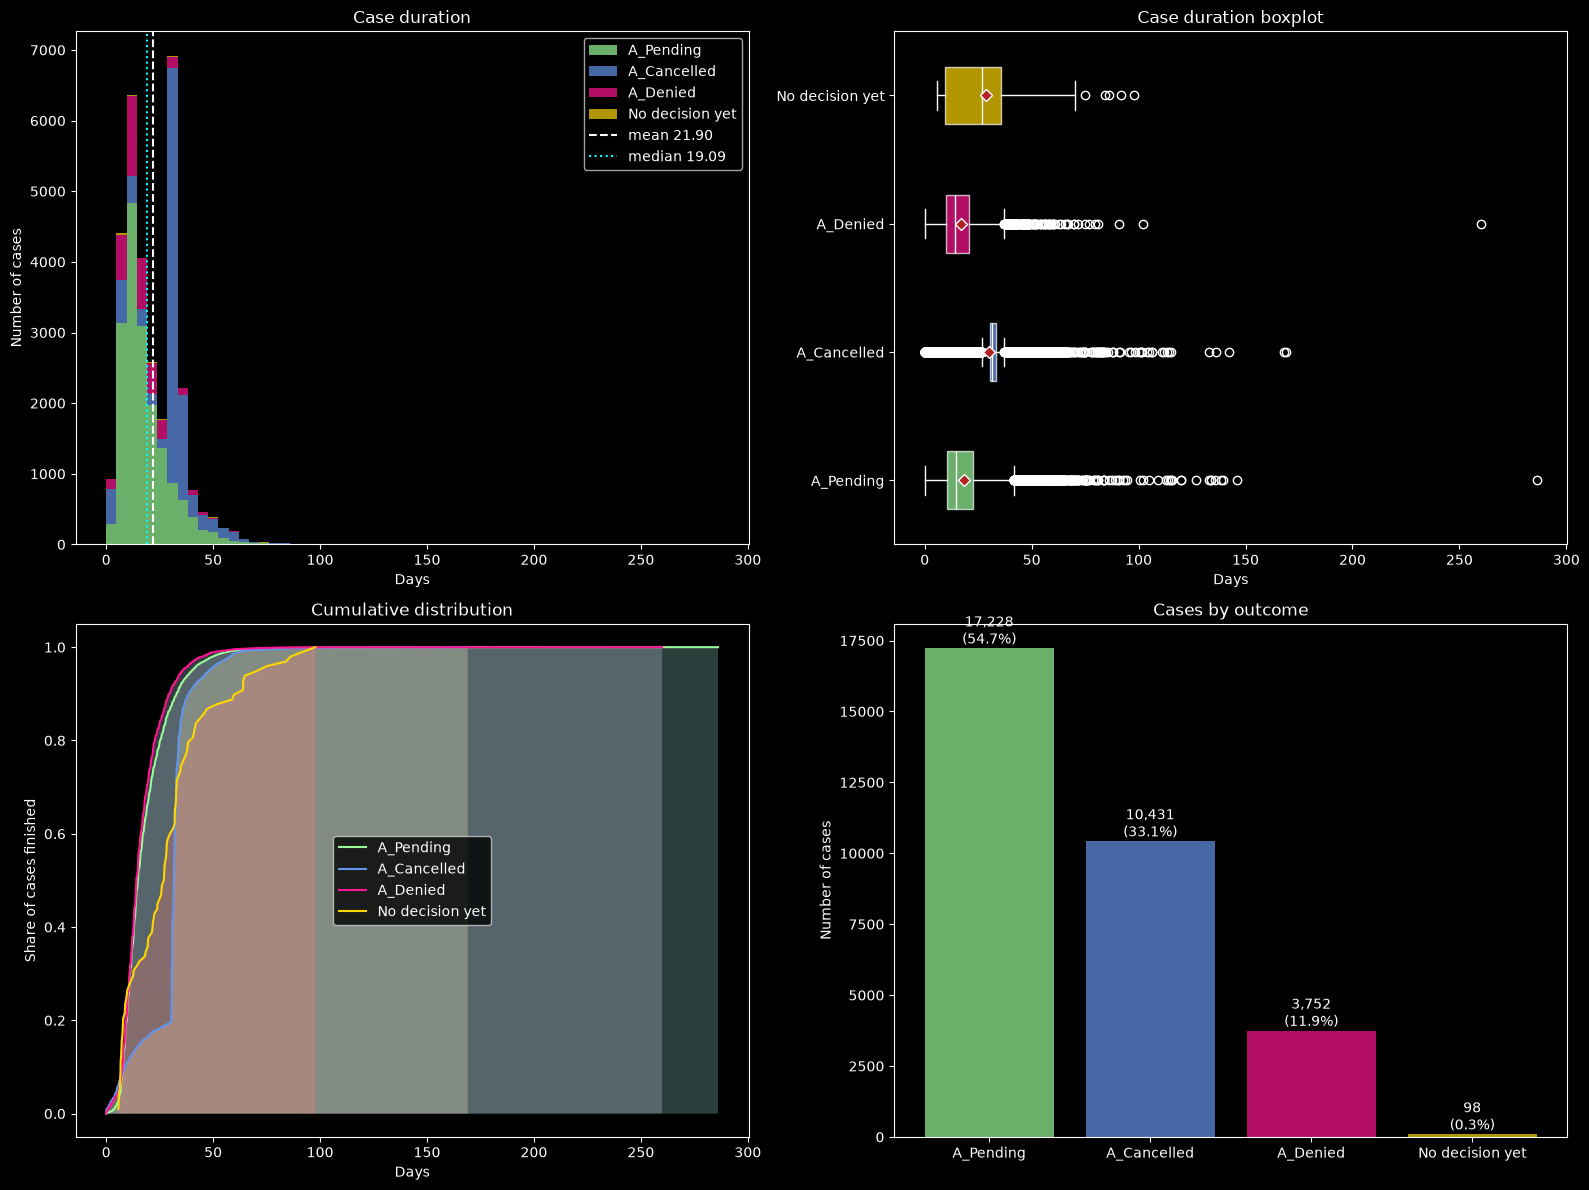

In [24]:
duration_in_days = cases["duration_days"]

plt.style.use('dark_background')
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# For the outcome
order = ["A_Pending",
         "A_Cancelled",
         "A_Denied",
         "No decision yet"]
colors = {"A_Pending": "palegreen", 
          "A_Cancelled": "cornflowerblue",
          "A_Denied": "deeppink", 
          "No decision yet": "gold"}

# It is required one duration series per outcome, in a fixed order!
groups = {o: cases.loc[cases["outcome"] == o, "duration_days"] for o in order}

# Histogram 

# To have same bin edges for every group
bins = np.histogram_bin_edges(duration_in_days, bins=60)  

axes[0][0].hist(list(groups.values()), # a list of series, one per outcome                   
                bins=bins,
                stacked=True,
                color=[colors[o] for o in order],
                alpha=0.7,
                label=order)
axes[0][0].set(title="Case duration",
               xlabel="Days",
               ylabel="Number of cases")
axes[0][0].axvline(duration_in_days.mean(),
                   linestyle="--",
                   color="white",                          
                   label=f"mean {duration_in_days.mean():.2f}")
axes[0][0].axvline(duration_in_days.median(),
                   linestyle=":",
                   color="cyan",                          
                   label=f"median {duration_in_days.median():.2f}")
axes[0][0].legend()

# Boxplot (one box per outcome)
meanpointprops = dict(marker='D',
                      markeredgecolor="white",
                      markerfacecolor="firebrick")
bp = axes[0][1].boxplot(list(groups.values()),
                        tick_labels=order,               
                        meanprops=meanpointprops,
                        showmeans=True,
                        meanline=False, 
                        orientation="horizontal",
                        patch_artist=True)


for patch, o in zip(bp["boxes"], order): # To pair each box with an order
    patch.set_facecolor(colors[o])
    patch.set_alpha(0.7)
for median in bp["medians"]:
    median.set_color("white") # In order for medians to stay visible
axes[0][1].set(title="Case duration boxplot", xlabel="Days")

# ECDF - Empirical Cumulative Distribution Function (one curve per outcome)
for o in order:
    x = np.sort(groups[o].values)
    y = np.arange(1, len(x) + 1) / len(x)
    axes[1][0].plot(x, 
                    y, 
                    color=colors[o], 
                    label=o)
    axes[1][0].fill_between(x,y, alpha=0.3)
axes[1][0].set(title="Cumulative distribution",
               xlabel="Days",
               ylabel="Share of cases finished")
axes[1][0].legend()

# Cases by outcome

# First, we calculate the frequencies of each category
counts = cases["outcome"].value_counts().reindex(order) 
axes[1][1].bar(order, 
               counts.values, 
               color=[colors[o] for o in order],
               alpha=0.7)
for i, v in enumerate(counts.values):
    axes[1][1].text(i, v, f"{v:,}\n({v/len(cases):.1%})", ha="center", va="bottom")
axes[1][1].set(title="Cases by outcome", 
               ylabel="Number of cases")

plt.tight_layout()
plt.show()

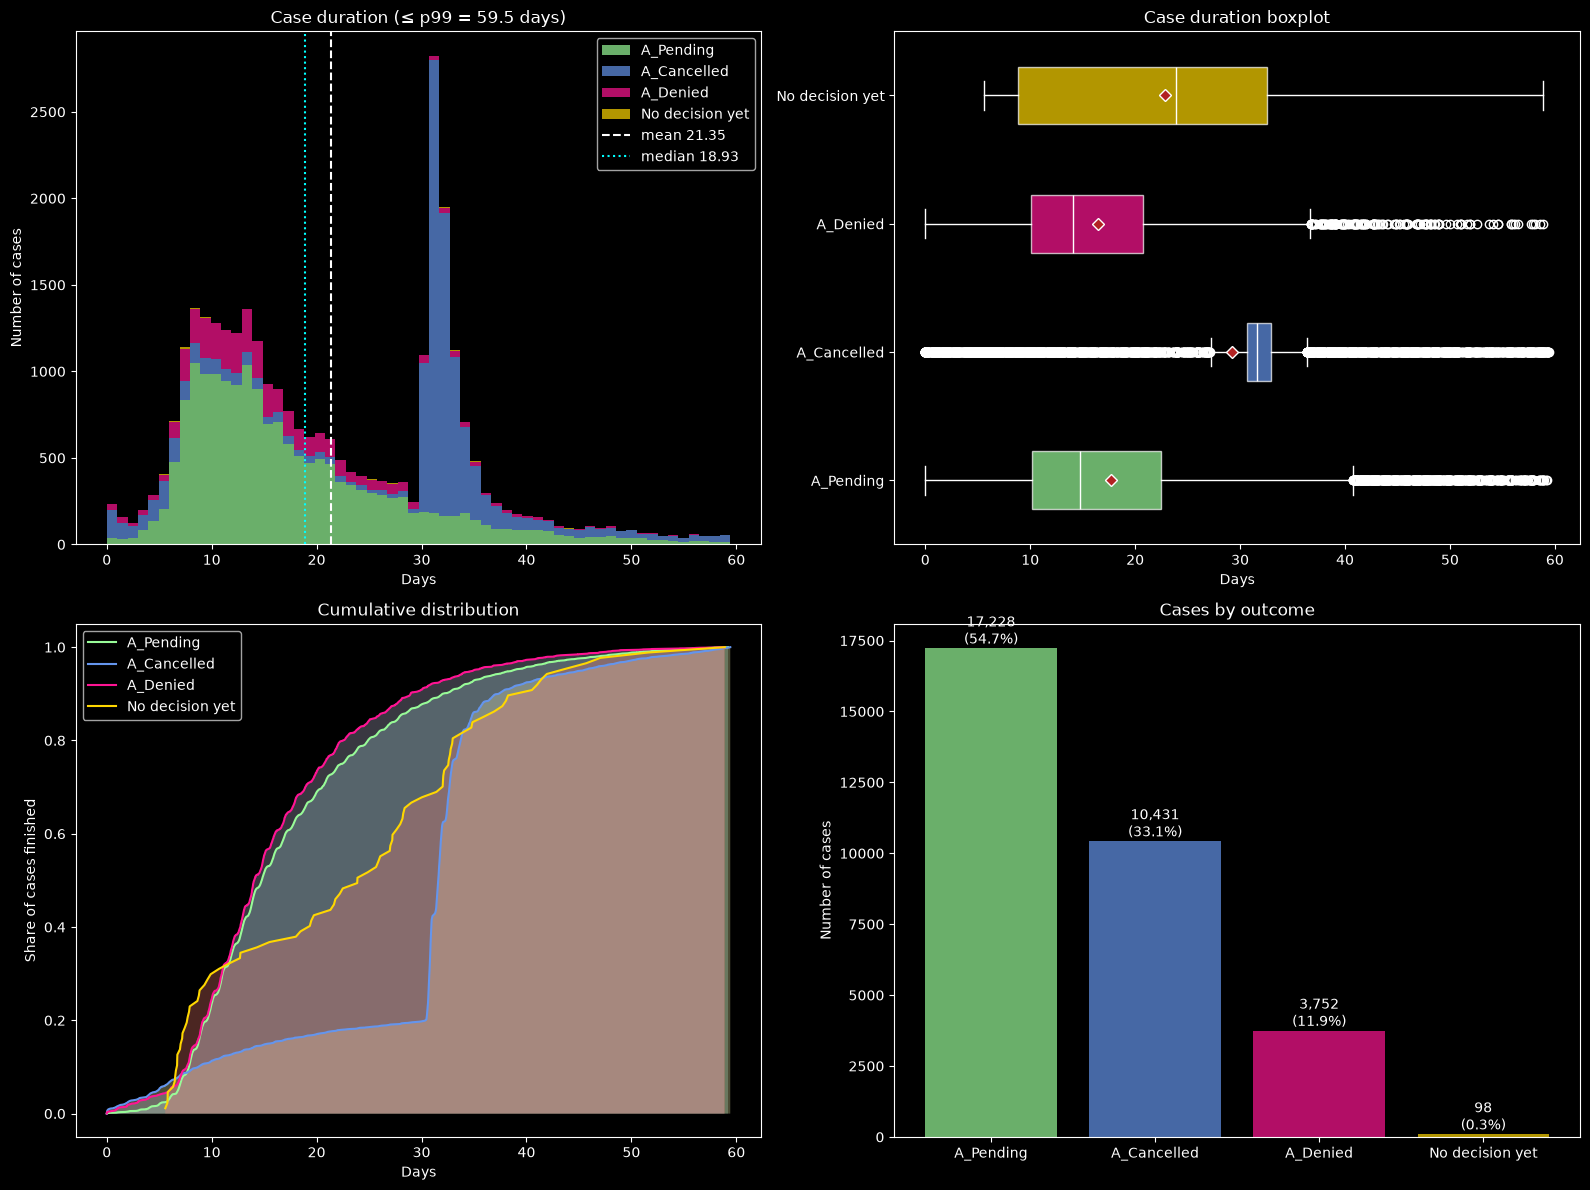

In [ ]:
# NOTE: Some graphs seemed skewed so I decided to leave out some 'outliers'ArithmeticError

# So we change the range in graphs with percentil 99
plt.style.use('dark_background')
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
p99 = cases["duration_days"].quantile(0.99)
shown = cases[cases["duration_days"] <= p99]
duration_in_days = shown["duration_days"]
groups = {o: shown.loc[shown["outcome"] == o, "duration_days"] for o in order}


# Everything else is the same 
# Histogram 

bins = np.histogram_bin_edges(duration_in_days, bins=60)  

axes[0][0].hist(list(groups.values()),                  
                bins=bins,
                stacked=True,
                color=[colors[o] for o in order],
                alpha=0.7,
                label=order)
axes[0][0].set(title=f"Case duration (≤ p99 = {p99:.1f} days)",
               xlabel="Days",
               ylabel="Number of cases")
axes[0][0].axvline(duration_in_days.mean(),
                   linestyle="--",
                   color="white",                          
                   label=f"mean {duration_in_days.mean():.2f}")
axes[0][0].axvline(duration_in_days.median(),
                   linestyle=":",
                   color="cyan",                          
                   label=f"median {duration_in_days.median():.2f}")
axes[0][0].legend()

# Boxplot 
meanpointprops = dict(marker='D',
                      markeredgecolor="white",
                      markerfacecolor="firebrick")
bp = axes[0][1].boxplot(list(groups.values()),
                        tick_labels=order,               
                        meanprops=meanpointprops,
                        showmeans=True,
                        meanline=False, 
                        orientation="horizontal",
                        patch_artist=True)


for patch, o in zip(bp["boxes"], order): 
    patch.set_facecolor(colors[o])
    patch.set_alpha(0.7)
for median in bp["medians"]:
    median.set_color("white") 
axes[0][1].set(title="Case duration boxplot", xlabel="Days")

# ECDF 
for o in order:
    x = np.sort(groups[o].values)
    y = np.arange(1, len(x) + 1) / len(x)
    axes[1][0].plot(x, 
                    y, 
                    color=colors[o], 
                    label=o)
    axes[1][0].fill_between(x,y, alpha=0.3)
axes[1][0].set(title="Cumulative distribution",
               xlabel="Days",
               ylabel="Share of cases finished")
axes[1][0].legend()

# Cases by outcome
counts = cases["outcome"].value_counts().reindex(order) 
axes[1][1].bar(order, 
               counts.values, 
               color=[colors[o] for o in order],
               alpha=0.7)
for i, v in enumerate(counts.values):
    axes[1][1].text(i, v, f"{v:,}\n({v/len(cases):.1%})", ha="center", va="bottom")
axes[1][1].set(title="Cases by outcome", 
               ylabel="Number of cases")

plt.tight_layout()
plt.savefig("generated_files/Case_duration_and_outcome_distribution.pdf", format="pdf")
plt.show()

#### **Outcome by loan attributes & by application type**

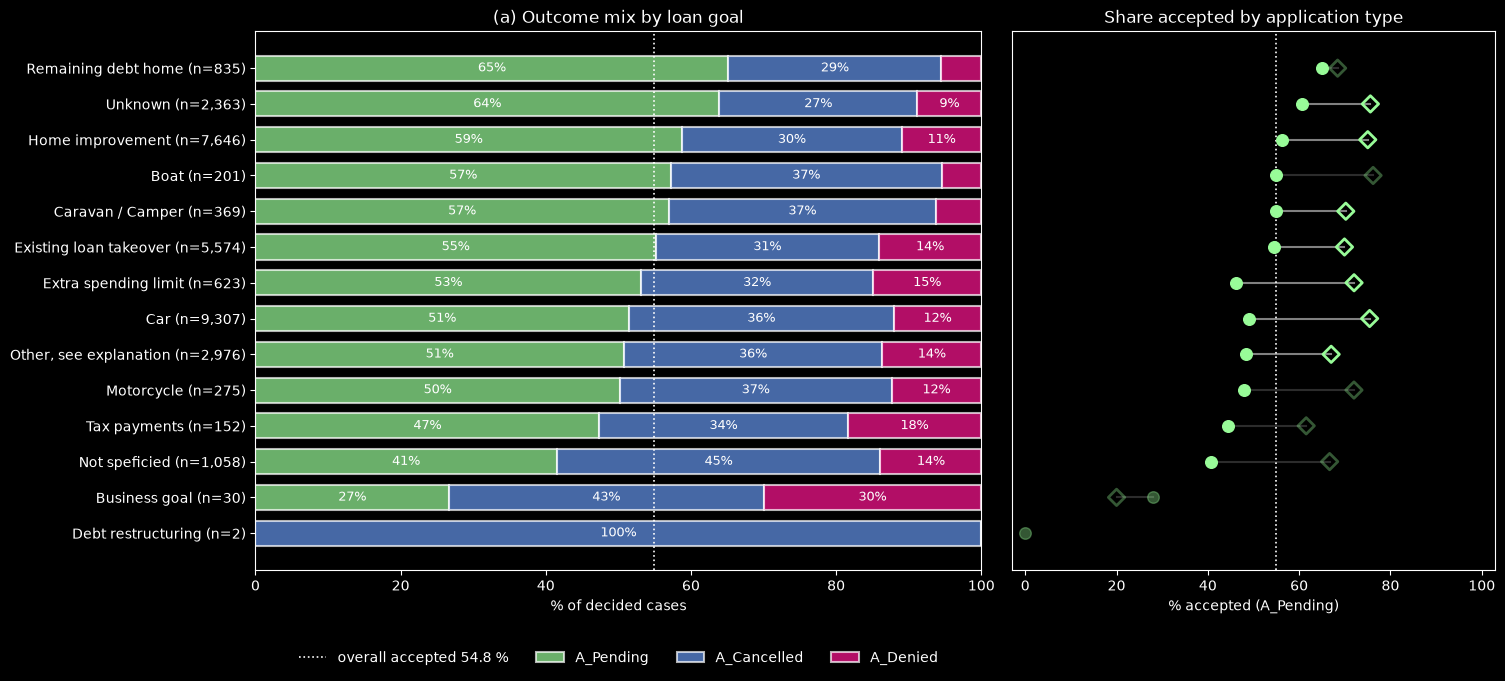

In [ ]:
outcome = ["A_Pending", 
          "A_Cancelled", 
          "A_Denied"]
# Same colors to keep coherence :)
colors = {"A_Pending": "palegreen", 
          "A_Cancelled": "cornflowerblue",
          "A_Denied": "deeppink"}

# For this we must only focus on decided cases
decided_cases = cases[cases["outcome"].isin(outcome)].copy() 
decided_cases["accepted"] = decided_cases["outcome"].eq("A_Pending") # Considering cases accepted this way
decided_cases["goal"] = decided_cases["loan_goal"]  

# Resume table (cross-tabulation): otcome mix + acceptance rate per application type
mix = pd.crosstab(decided_cases["goal"], 
                  decided_cases["outcome"], 
                  normalize="index")[outcome] * 100
by_app = decided_cases.groupby(["goal", "app_type"])["accepted"].agg(["mean", "size"]).unstack("app_type")
tab = mix.assign(n=decided_cases["goal"].value_counts())
tab["accepted_new_credit"] = by_app[("mean", "New credit")] * 100
tab["accepted_limit_raise"] = by_app[("mean", "Limit raise")] * 100
tab["share_limit_raise"] = by_app[("size", "Limit raise")] / tab["n"] * 100
tab = tab.sort_values("A_Pending")    

plt.style.use("dark_background")
fig, (ax1, ax2) = plt.subplots(1, 2, 
                               figsize=(16, 7), 
                               sharey=True,
                               gridspec_kw={"width_ratios": [1.5, 1], "wspace": 0.05})
y = np.arange(len(tab))
labels = [f"{g} (n={int(n):,})" for g, n in zip(tab.index, tab["n"])]

# Stacked bars
left = np.zeros(len(tab))
for o in outcome:
    ax1.barh(y, 
             tab[o], 
             left=left, 
             color=colors[o], 
             height=0.7, 
             label=o, 
             edgecolor="white", 
             linewidth=1.5,
             alpha=0.7)
    for yi, (l, w) in enumerate(zip(left, tab[o])):
        if w >= 8:
            ax1.text(l + w / 2, yi, f"{w:.0f}%", ha="center", va="center", fontsize=9, color="white")
    left += tab[o].values

# Overall calculation
overall = decided_cases["accepted"].mean() * 100
ax1.axvline(overall, 
            color="white", 
            linestyle=":", 
            linewidth=1.2, 
            label=f"overall accepted {overall:.1f} %")
ax1.set(xlim=(0, 100),
        xlabel="% of decided cases", 
        title="(a) Outcome mix by loan goal")
ax1.set_yticks(y)
ax1.set_yticklabels(labels)
ax1.legend(loc="lower center", 
           bbox_to_anchor=(0.5, -0.2), 
           ncol=4, 
           frameon=False)

# Dumbbel "by application type"
# For visualization purposes dots based on fewer cases than this are drawn faded 
fade_low = 35

for yi, g in enumerate(tab.index):
    ### acceptance rates
    nc, lr = tab.loc[g, "accepted_new_credit"], tab.loc[g, "accepted_limit_raise"]
    ###
    ## sample sizes
    n_lr = by_app.loc[g, ("size", "Limit raise")]
    n_nc = by_app.loc[g, ("size", "New credit")]
    ##
    show_lr = pd.notna(lr) # NOTE: No Limit raise cases for a goal => no diamond
    show_nc = pd.notna(nc)
    a_lr = 1.0 if show_lr and n_lr >= fade_low else 0.35
    a_nc = 1.0 if show_nc and n_nc >= fade_low else 0.35
    if show_lr and show_nc:
        ax2.plot([nc, lr], [yi, yi], 
                 color="grey", 
                 linewidth=1.5, 
                 alpha=min(a_lr, a_nc), 
                 zorder=1)
    if show_lr:
        ax2.scatter(lr, yi, 
                    marker="D", 
                    s=70, 
                    facecolors="none", 
                    edgecolors=colors["A_Pending"],
                    linewidths=2, 
                    alpha=a_lr, zorder=3)
    if show_nc:
        ax2.scatter(nc, yi, 
                    marker="o", 
                    s=70, 
                    color=colors["A_Pending"], 
                    alpha=a_nc, 
                    zorder=3)
ax2.axvline(overall, 
            color="white", 
            linestyle=":", 
            linewidth=1.2)
ax2.set(xlim=(-3, 103), 
        xlabel="% accepted (A_Pending)", 
        title="Share accepted by application type")
ax2.tick_params(axis="y", left=False)

plt.savefig("generated_files/Outcome_by_loan_attributes_by_application_type.pdf", format="pdf")
plt.show()


### **3.3 Process Model Creation and Validation**

In [27]:
# This is just a change of name because we have previously used log for original EventLog 
log_c = df[df["lifecycle:transition"] == "complete"].copy()
print(len(log_c), log_c["case:concept:name"].nunique())
log_c = log_c.sort_values([case, timestamp], kind="stable")  # NOTE: In case of draw we keep original log order


475306 31509


### **3.4 Advanced Analysis**

#### **Alpha Miner**

In [ ]:
alpha, ini_mark_alpha, fin_mark_alpha = pm4py.discover_petri_net_alpha(log_c,
                                                                       activity_key=act,
                                                                       timestamp_key=timestamp,
                                                                       case_id_key=case)

print("Alpha+ model:",
      f"{len(alpha.places)} places,",
      f"{len(alpha.transitions)} transitions,",
      f"{len(alpha.arcs)} arcs")

# Petri net for the appendix
pm4py.write_pnml(alpha, ini_mark_alpha, fin_mark_alpha,"generated_files/alpha_model.pnml")

Alpha+ model: 25 places, 24 transitions, 87 arcs


#### **Heuristic Miner**

In [ ]:
heuristics, ini_mark_heuristics, fin_mark_heuristics = pm4py.discover_petri_net_heuristics(log_c,
                                                                                           activity_key=act,
                                                                                           timestamp_key=timestamp,
                                                                                           case_id_key=case)

print("Heuristics model:",
      f"{len(heuristics.places)} places,",
      f"{len(heuristics.transitions)} transitions,",
      f"{len(heuristics.arcs)} arcs")

pm4py.write_pnml(heuristics, ini_mark_heuristics, fin_mark_heuristics,"generated_files/heuristics_model.pnml")


Heuristics model: 49 places, 94 transitions, 220 arcs


#### **Inductive Miner**

In [ ]:
inductive, ini_mark_inductive, fin_mark_inductive = pm4py.discover_petri_net_inductive(log_c,                                                                         
                                                                                       activity_key=act,
                                                                                       timestamp_key=timestamp,
                                                                                       case_id_key=case)

print("Inductive model:",
      f"{len(inductive.places)} places,",
      f"{len(inductive.transitions)} transitions,",
      f"{len(inductive.arcs)} arcs")


pm4py.write_pnml(inductive, ini_mark_inductive, fin_mark_inductive,"generated_files/inductive_model.pnml")

Inductive model: 34 places, 53 transitions, 114 arcs


#### **PM4Py quality metrics (fitness,precision, generalization,simplicity)**

In [31]:
def custom_simplicity_metrics(net):
    n_places = len(net.places)
    n_transitions = len(net.transitions)
    n_arcs = len(net.arcs)

    # Custom metric 1: total structural elements (lower = smaller model)
    structural_size = n_places + n_transitions + n_arcs

    # Custom metric 2: mean in-degree + out-degree per transition
    if n_transitions:
        mean_transition_degree = np.mean([
            len(t.in_arcs) + len(t.out_arcs) for t in net.transitions
        ])
    else:
        mean_transition_degree = np.nan

    return structural_size, mean_transition_degree


models = {
    "Alpha Miner+": (net_alpha_plus, im_alpha_plus, fm_alpha_plus),
    "Heuristics Miner": (net_heuristics, im_heuristics, fm_heuristics),
    "Inductive Miner": (net_inductive, im_inductive, fm_inductive),
}

rows = []

for model_name, (net, im, fm) in models.items():
    print(f"Evaluating {model_name} ...")

    # PM4Py token-based replay fitness returns a dictionary.
    fitness_result = pm4py.fitness_token_based_replay(
        log_c, net, im, fm,
        activity_key=act,
        timestamp_key=timestamp,
        case_id_key=case
    )
    fitness = fitness_result.get("log_fitness", np.nan)

    precision = pm4py.precision_token_based_replay(
        log_c, net, im, fm,
        activity_key=act,
        timestamp_key=timestamp,
        case_id_key=case
    )

    generalization = pm4py.generalization_tbr(
        log_c, net, im, fm,
        activity_key=act,
        timestamp_key=timestamp,
        case_id_key=case
    )

    # PM4Py's official simplicity metric; if unavailable in the installed
    # version, preserve the rest of the results and mark this field NaN.
    try:
        simplicity_pm4py = pm4py.simplicity_petri_net(net)
    except (AttributeError, TypeError, NotImplementedError):
        simplicity_pm4py = np.nan

    structural_size, mean_transition_degree = custom_simplicity_metrics(net)

    rows.append({
        "Model": model_name,
        "Fitness (log)": fitness,
        "Precision (token replay)": precision,
        "Generalization (TBR)": generalization,
        "Simplicity (PM4Py)": simplicity_pm4py,
        "Structural size (custom; lower=smaller)": structural_size,
        "Mean transition degree (custom; lower=simpler)": mean_transition_degree,
        "Places": len(net.places),
        "Transitions": len(net.transitions),
        "Arcs": len(net.arcs),
    })

quality_results = pd.DataFrame(rows).set_index("Model")
display(quality_results.round(4))


NameError: name 'net_alpha_plus' is not defined

### **Option 2: Advanced Data Science Analysis**